In [2]:
import xarray as xr
import netCDF4,os,re,copy,glob
import numpy as np
import matplotlib.pyplot as plt
from EMIT_lib import *
import pickle 
import cartopy
import sys,os
import cartopy.crs as crs
import cartopy.feature as cfeature
import matplotlib.ticker as mticker
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import awscli, s3fs, boto3
import requests
import xarray as xr
import hvplot.xarray
import holoviews as hv
from AWS_Utils import get_NASA_creds

## get OB data credentials

In [5]:
obdaac_creds = get_NASA_creds('obdaac')
fs_s3 = s3fs.S3FileSystem(anon=False, 
                          key=obdaac_creds['accessKeyId'], 
                          secret=obdaac_creds['secretAccessKey'], 
                          token=obdaac_creds['sessionToken'])

In [7]:
OCI_L1B_fn='s3://ob-cumulus-prod-public/PACE_OCI.20240411T132512.L1B.nc'
s3_file_obj = fs_s3.open(OCI_L1B_fn, mode='rb')
OCI_l1b=xr.open_dataset(s3_file_obj,group='observation_data')
OCI_sbp=xr.open_dataset(s3_file_obj,group='sensor_band_parameters')

In [8]:
B=OCI_l1b.rhot_blue[56,:,:]
G=OCI_l1b.rhot_blue[97,:,:]
R=OCI_l1b.rhot_red[20,:,:]
print(B.shape,G.shape,R.shape)



(1710, 1272) (1710, 1272) (1710, 1272)



<xarray.DataArray 'rhot_blue' ()> Size: 8B
array(0.95943904) <xarray.DataArray 'rhot_blue' ()> Size: 8B
array(0.96232128) <xarray.DataArray 'rhot_red' ()> Size: 8B
array(0.99117571)
<xarray.DataArray 'rhot_blue' ()> Size: 8B
array(0.09358923) <xarray.DataArray 'rhot_blue' ()> Size: 8B
array(0.05138967) <xarray.DataArray 'rhot_red' ()> Size: 8B
array(0.02905706)


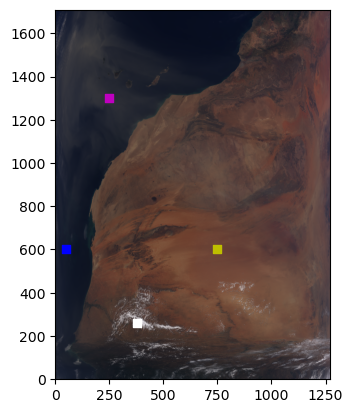

In [31]:
# fig,ax=plt.subplots()
# ax.imshow(R[:600,:],vmin=0,vmax=1.0,cmap='gray')

# fig,ax=plt.subplots()
# ax.imshow(G[:600,:],vmin=0,vmax=1.0,cmap='gray')


# fig,ax=plt.subplots()
# ax.imshow(B[:600,:],vmin=0,vmax=1.0,cmap='gray')

n1,n2=R.shape
RGB=np.zeros([n1,n2,3])
print()
RGB[:,:,0]=R*255
RGB[:,:,1]=G*255
RGB[:,:,2]=B*255
#print(RGB)
print(B.max(),G.max(),R.max())
print(B.min(),G.min(),R.min())

RGB_image=np.array(RGB, dtype=np.uint8)

fig,ax=plt.subplots()
ax.imshow(RGB_image[:,:,:],origin='lower')
land_x,land_y=750,600
dust_x,dust_y=250,1300
clear_x,clear_y=50,600
cloud_x,cloud_y=380,260
ax.scatter([land_x],[land_y],marker='s',facecolor='y')
ax.scatter([dust_x],[dust_y],marker='s',facecolor='m')
ax.scatter([clear_x],[clear_y],marker='s',facecolor='b')
ax.scatter([cloud_x],[cloud_y],marker='s',facecolor='w')
fig.savefig('PACE_OCI_RGB.png',dpi=300)

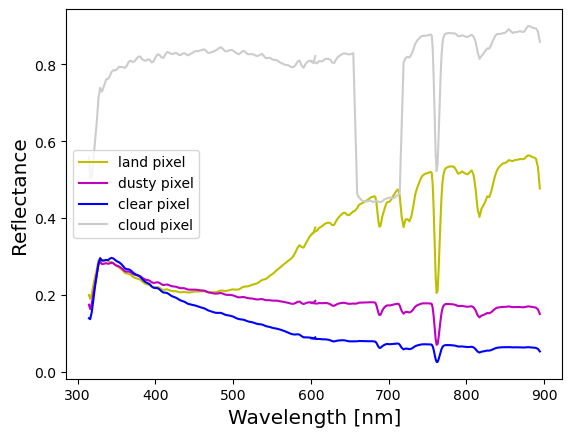

In [33]:
land_x,land_y=750,600
dust_x,dust_y=250,1300
clear_x,clear_y=50,600
fig,ax=plt.subplots()
ax.plot(OCI_sbp.blue_wavelength.values,OCI_l1b.rhot_blue[:,land_y,land_x].values,c='y')
ax.plot(OCI_sbp.blue_wavelength.values,OCI_l1b.rhot_blue[:,dust_y,dust_x].values,c='m')
ax.plot(OCI_sbp.blue_wavelength.values,OCI_l1b.rhot_blue[:,clear_y,clear_x].values,c='b')
ax.plot(OCI_sbp.blue_wavelength.values,OCI_l1b.rhot_blue[:,cloud_y,cloud_x].values,c='0.8')

ax.plot(OCI_sbp.red_wavelength.values,OCI_l1b.rhot_red[:,land_y,land_x].values,c='y',label='land pixel')
ax.plot(OCI_sbp.red_wavelength.values,OCI_l1b.rhot_red[:,dust_y,dust_x].values,c='m',label='dusty pixel')
ax.plot(OCI_sbp.red_wavelength.values,OCI_l1b.rhot_red[:,clear_y,clear_x].values,c='b',label='clear pixel')
ax.plot(OCI_sbp.red_wavelength.values,OCI_l1b.rhot_red[:,cloud_y,cloud_x].values,c='0.8',label='cloud pixel')


ax.legend()
ax.set_xlabel('Wavelength [nm]',fontsize='x-large')
ax.set_ylabel('Reflectance',fontsize='x-large')
fig.savefig('pixel_spectrum.png',dpi=300)